<a href="https://colab.research.google.com/github/KarthikSaravanakumarM56/24ADI006-24BAD056-DL/blob/main/DL_Lab_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#EXPERIMENT NO: 8
#TRAIN A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING
PART A: DATASET PREPARATION AND PREPROCESSING

Training Images: (60000, 28, 28)
Testing Images: (10000, 28, 28)
Number of Training Images: 60000
Number of Testing Images: 10000
Image Dimensions: (28, 28)


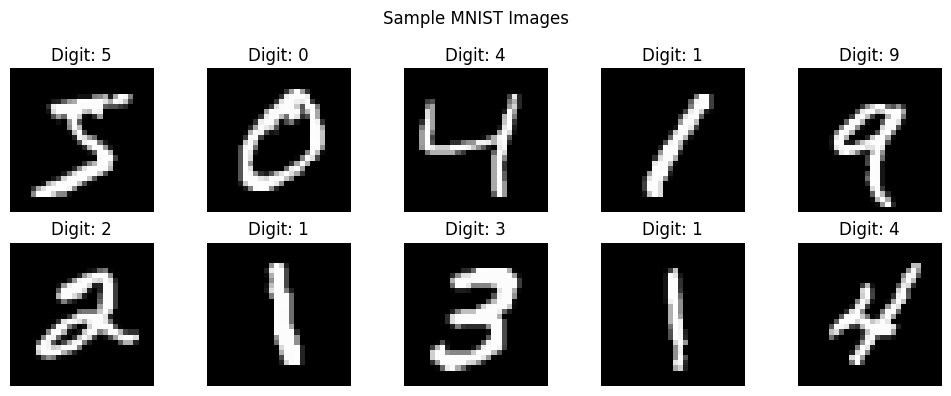


After Preprocessing:
Training Data Shape: (60000, 784)
Testing Data Shape: (10000, 784)
Input Dimension: 784
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


In [5]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar
# Experiment 8 - Part A

!pip install scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Explore dataset
print("Training Images:", x_train.shape)
print("Testing Images:", x_test.shape)
print("Number of Training Images:", len(x_train))
print("Number of Testing Images:", len(x_test))
print("Image Dimensions:", x_train[0].shape)

# Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title("Digit: " + str(y_train[i]))
    plt.axis('off')
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()

# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Flatten images into 784 features
x_train = x_train.reshape(-1, 784)
x_test = x_test.reshape(-1, 784)

# Input and target data
train_data = x_train
test_data = x_test

print("\nAfter Preprocessing:")
print("Training Data Shape:", train_data.shape)
print("Testing Data Shape:", test_data.shape)
print("Input Dimension:", train_data.shape[1])
print("Minimum Pixel Value:", train_data.min())
print("Maximum Pixel Value:", train_data.max())

PART B: IMPLEMENTING THE ENCODER AND DECODER

In [6]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar
# Experiment 8 - Part B

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense

# Define dimensions
input_dim = 784
latent_dim = 32

# Encoder
input_layer = Input(shape=(input_dim,))
encoder_hidden = Dense(128, activation='relu')(input_layer)
latent_layer = Dense(latent_dim,
                     activation='relu',
                     name='Latent_Layer')(encoder_hidden)
encoder = Model(input_layer, latent_layer, name='Encoder')

# Decoder
decoder_input = Input(shape=(latent_dim,))
decoder_hidden = Dense(128, activation='relu')(decoder_input)
decoder_output = Dense(input_dim,
                       activation='sigmoid')(decoder_hidden)
decoder = Model(decoder_input, decoder_output, name='Decoder')

# Combine encoder and decoder
autoencoder_output = decoder(encoder(input_layer))
autoencoder = Model(input_layer,
                    autoencoder_output,
                    name='Autoencoder')

# Display model summaries
print("ENCODER SUMMARY")
encoder.summary()
print("\nDECODER SUMMARY")
decoder.summary()
print("\nAUTOENCODER SUMMARY")
autoencoder.summary()

ENCODER SUMMARY


Model: "Encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Latent_Layer (Dense)            │ (None, 32)             │         4,128 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,608 (408.62 KB)

 Trainable params: 104,608 (408.62 KB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Encoder (Functional)            │ (None, 32)             │       104,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Decoder (Functional)            │ (None, 784)            │       105,360 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

PART C: COMPILING AND TRAINING THE AUTOENCODER

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - loss: 0.2291 - val_loss: 0.1511
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 34ms/step - loss: 0.1366 - val_loss: 0.1238
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - loss: 0.1193 - val_loss: 0.1124
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - loss: 0.1100 - val_loss: 0.1052
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 12s 37ms/step - loss: 0.1042 - val_loss: 0.1010
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1008 - val_loss: 0.0983
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - loss: 0.0985 - val_loss: 0.0964
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 32ms/step - loss: 0.0968 - val_loss: 0.0950
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0953 - val_loss: 0.0935
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0942 - val_loss: 0.0925

Final Training Loss: 0.09421271085739136
Final Validation Loss: 0.09252414852380753


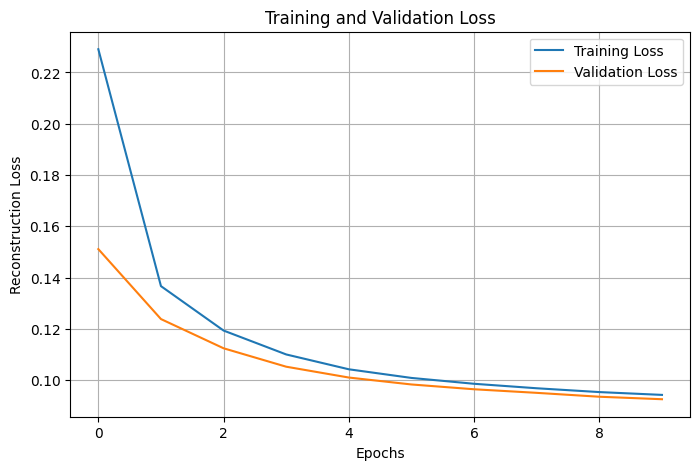

In [7]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar
# Experiment 8 - Part C

# Compile the autoencoder
autoencoder.compile(
    optimizer='adam',
    loss='binary_crossentropy'
)

# Train the autoencoder
history = autoencoder.fit(
    train_data,
    train_data,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(test_data, test_data)
)

# Display final losses
print("\nFinal Training Loss:",
      history.history['loss'][-1])
print("Final Validation Loss:",
      history.history['val_loss'][-1])

# Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Reconstruction Loss")
plt.legend()
plt.grid(True)
plt.show()

PART D: DIMENSIONALITY REDUCTION, FEATURE LEARNING AND RECONSTRUCTION

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 186ms/step
Original Input Dimension: 784
Latent Dimension: 32
Original Data Shape: (10, 784)
Latent Features Shape: (10, 32)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step
Reconstructed Data Shape: (10, 784)


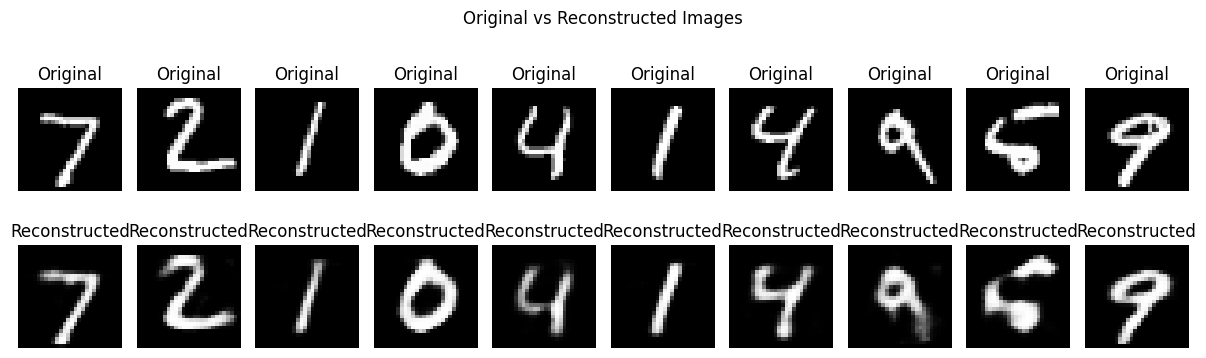

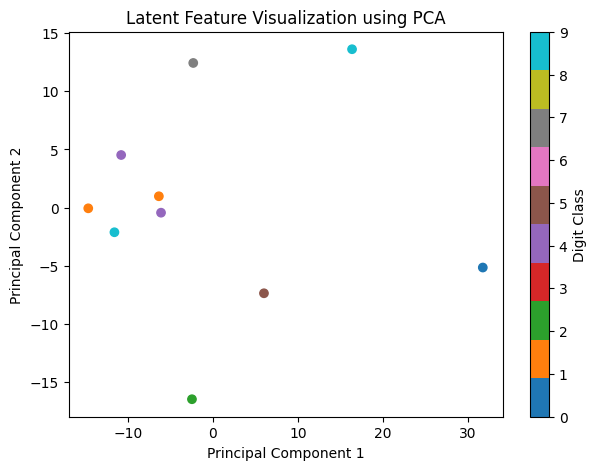

Mean Squared Reconstruction Error: 0.009980373

All Models and Reconstructed Images Saved Successfully!


In [8]:
# Roll No: 24BAD056
# Name: M. Karthik Saravanakumar
# Experiment 8 - Part D

from sklearn.decomposition import PCA

# Select test images
sample_data = test_data[:10]

# Extract latent features
latent_features = encoder.predict(sample_data)

# Display dimensions
print("Original Input Dimension:", 784)
print("Latent Dimension:", 32)

print("Original Data Shape:", sample_data.shape)
print("Latent Features Shape:", latent_features.shape)

# Reconstruct images using decoder
reconstructed_images = decoder.predict(latent_features)
print("Reconstructed Data Shape:",
      reconstructed_images.shape)

# Display original and reconstructed images
plt.figure(figsize=(12, 4))
for i in range(10):

    # Original image
    plt.subplot(2, 10, i + 1)
    plt.imshow(sample_data[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed image
    plt.subplot(2, 10, i + 11)
    plt.imshow(reconstructed_images[i].reshape(28, 28), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')
plt.suptitle("Original vs Reconstructed Images")
plt.tight_layout()
plt.show()

# PCA visualization of latent features
pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_features)
plt.figure(figsize=(7, 5))
plt.scatter(
    latent_2d[:, 0],
    latent_2d[:, 1],
    c=y_test[:10],
    cmap='tab10'
)
plt.colorbar(label='Digit Class')
plt.title("Latent Feature Visualization using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Calculate reconstruction error
mse = np.mean((sample_data - reconstructed_images) ** 2)
print("Mean Squared Reconstruction Error:", mse)

# Save trained models
autoencoder.save("autoencoder_model.keras")
encoder.save("encoder_model.keras")
decoder.save("decoder_model.keras")

# Save reconstructed images
np.save("reconstructed_images.npy", reconstructed_images)
print("\nAll Models and Reconstructed Images Saved Successfully!")